# ĐỒ ÁN / BÀI TẬP: PHÁT HIỆN XÂM NHẬP MẠNG IOT (IoT-NIDS)
## Bộ dữ liệu: IoT-23 Dataset (Stratosphere Laboratory / CTU University)
---
### Các nội dung chính trong Notebook:
1. **EDA (Khám phá dữ liệu)**: Phân bố nhãn, Phân tích trạng thái kết nối TCP (`conn_state`), Top cổng đích bị tấn công (`id.resp_p`).
2. **Làm rõ nghi vấn Data Leakage / Shortcut Learning**: Giải thích vì sao mô hình dễ đạt F1-Score ~ 100%.
3. **Tiền xử lý (Preprocessing)**: Làm sạch ký tự rỗng của Zeek log, Label Encoding, Data Scaling.
4. **Huấn luyện & Benchmark 5 mô hình ML**: Logistic Regression, Decision Tree, Random Forest, XGBoost, LightGBM.
5. **Thử nghiệm đối chứng (Ablation Study)**: Huấn luyện lại khi loại bỏ các đặc trưng shortcut để đo độ chính xác thực tế.

In [1]:
# 1. KHAI BÁO THƯ VIỆN
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb
import lightgbm as lgb

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.figsize"] = (10, 6)
print("[+] Thư viện đã nạp thành công!")

[+] Thư viện đã nạp thành công!


---
## 2. NẠP DỮ LIỆU IOT-23 THỰC TẾ (Zeek / Bro conn.log Format)
Đọc trực tiếp file log thực tế: `CTU-IoT-Malware-Capture-3-1_conn.log.labeled`.

In [2]:
ZEEK_COLUMNS = [
    "ts", "uid", "id.orig_h", "id.orig_p", "id.resp_h", "id.resp_p",
    "proto", "service", "duration", "orig_bytes", "resp_bytes",
    "conn_state", "local_orig", "local_resp", "missed_bytes",
    "history", "orig_pkts", "orig_ip_bytes", "resp_pkts",
    "resp_ip_bytes", "tunnel_parents", "label", "detailed-label"
]

data_path = r"c:\Study\HocKy6\IoT_NIDS_Pipeline\CTU-IoT-Malware-Capture-9-1_conn.log.labeled"

# Đọc 100,000 dòng đầu tiên để chạy mượt mà và trực quan
df = pd.read_csv(
    data_path,
    sep=r"\s+",
    comment="#",
    names=ZEEK_COLUMNS,
    nrows=1000000,
    low_memory=False
)

print(f"[+] Đã tải {len(df):,} dòng dữ liệu mạng.")
df.head(5)

[+] Đã tải 1,000,000 dòng dữ liệu mạng.


,ts,uid,id.orig_h,id.orig_p,id.resp_h,id.resp_p,proto,service,duration,orig_bytes,...,local_resp,missed_bytes,history,orig_pkts,orig_ip_bytes,resp_pkts,resp_ip_bytes,tunnel_parents,label,detailed-label
0,1.532510e+09,CnR6zKxrWbFw26ua7,192.168.100.111,40008,46.28.110.244,123,udp,-,0.004751,48,...,-,0,Dd,1,76,1,76,(empty),Benign,-
1,1.532511e+09,CcfURS3zgEMzX0RqTc,192.168.100.102,57849,192.168.100.111,22,tcp,-,108.421563,2376,...,-,0,DAd,5,332,2,200,(empty),Benign,-
2,1.532512e+09,CPhAqD1EhNOoPVA6ha,192.168.100.102,59670,192.168.100.111,22,tcp,-,0.001244,21,...,-,0,SAD,3,189,0,0,(empty),Benign,-
3,1.532512e+09,CFr56iYeYk4YZXrPf,192.168.100.102,59701,192.168.100.111,22,tcp,-,0.000738,21,...,-,0,SAD,3,189,0,0,(empty),Benign,-
4,1.532512e+09,C8a9xW23hF8nDgeNtj,192.168.100.111,36199,192.168.100.1,53,udp,dns,-,-,...,-,0,D,1,58,0,0,(empty),Benign,-


---
## 3. KHÁM PHÁ VÀ PHÂN TÍCH DỮ LIỆU (EDA - Exploratory Data Analysis)

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_11580\2813914781.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts.index, y=counts.values, palette=["#e74c3c", "#2ecc71"], ax=ax[0])


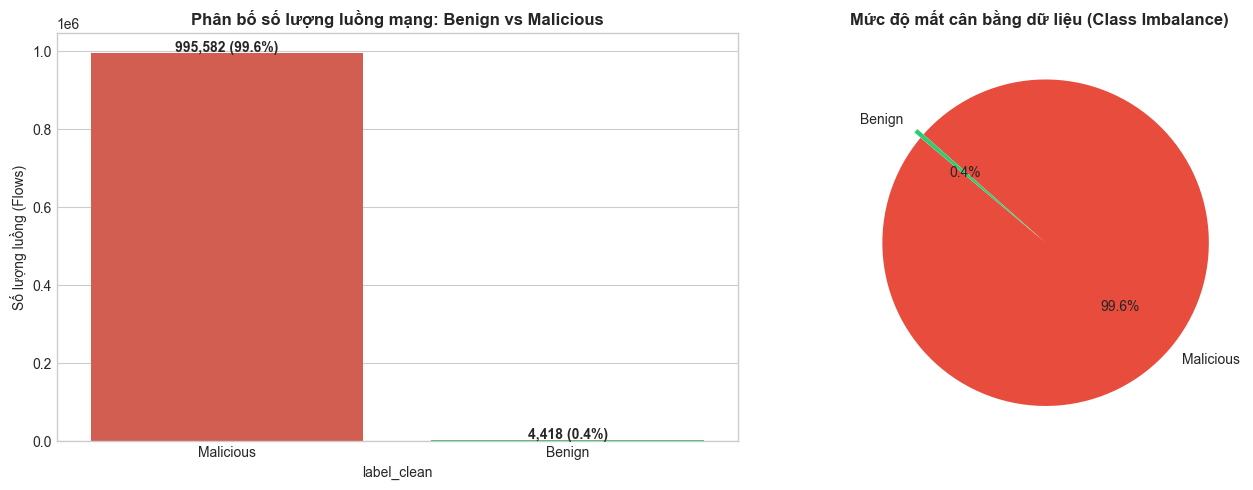

In [3]:
# 3.1 Phân bố nhãn mục tiêu (Class Distribution)
df["label_clean"] = df["label"].apply(lambda x: "Benign" if "benign" in str(x).lower() else "Malicious")
counts = df["label_clean"].value_counts()

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(x=counts.index, y=counts.values, palette=["#e74c3c", "#2ecc71"], ax=ax[0])
ax[0].set_title("Phân bố số lượng luồng mạng: Benign vs Malicious", fontsize=12, fontweight="bold")
ax[0].set_ylabel("Số lượng luồng (Flows)")
for i, v in enumerate(counts.values):
    ax[0].text(i, v + 1000, f"{v:,} ({v/len(df)*100:.1f}%)", ha="center", fontweight="bold")

ax[1].pie(counts.values, labels=counts.index, autopct="%1.1f%%", startangle=140, colors=["#e74c3c", "#2ecc71"], explode=(0.05, 0))
ax[1].set_title("Mức độ mất cân bằng dữ liệu (Class Imbalance)", fontsize=12, fontweight="bold")

plt.tight_layout()
plt.show()

Tỷ lệ % trạng thái kết nối TCP:


label_clean,Benign,Malicious
conn_state,,
OTH,9.76,0.0
REJ,14.28,0.0
RSTO,0.59,0.0
RSTR,0.09,0.0
S0,65.50,100.0
S1,0.05,0.0
S2,0.02,0.0
SF,9.71,0.0


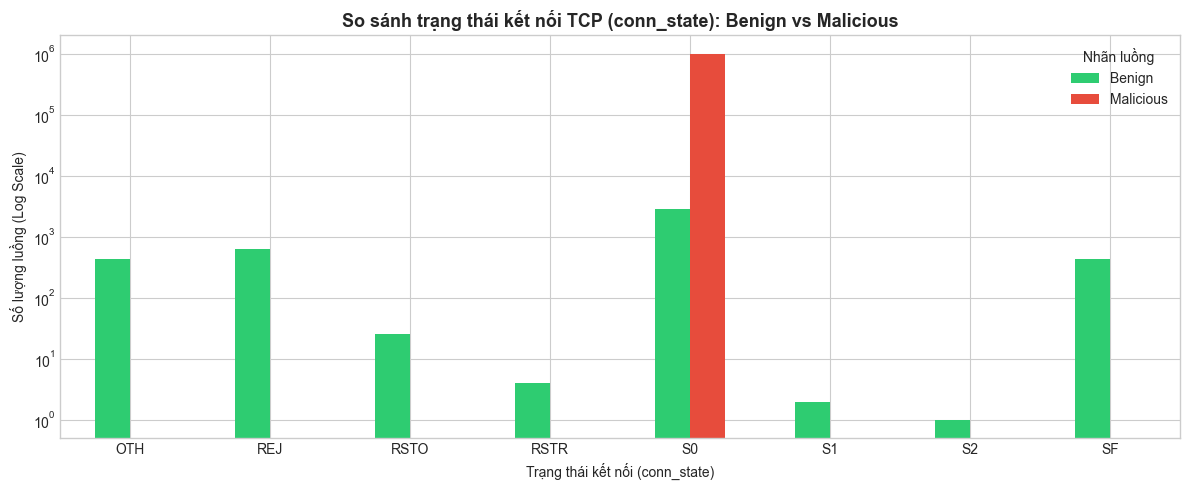

In [4]:
# 3.2 Phân tích trạng thái kết nối TCP (conn_state)
# GIẢI MÃ NGUYÊN NHÂN MÔ HÌNH ĐẠT 100%:
state_analysis = pd.crosstab(df["conn_state"], df["label_clean"], normalize="columns") * 100
print("Tỷ lệ % trạng thái kết nối TCP:")
display(state_analysis.round(2))

state_counts = pd.crosstab(df["conn_state"], df["label_clean"])
state_counts.plot(kind="bar", figsize=(12, 5), color=["#2ecc71", "#e74c3c"])
plt.title("So sánh trạng thái kết nối TCP (conn_state): Benign vs Malicious", fontsize=13, fontweight="bold")
plt.xlabel("Trạng thái kết nối (conn_state)")
plt.ylabel("Số lượng luồng (Log Scale)")
plt.yscale("log")
plt.xticks(rotation=0)
plt.legend(title="Nhãn luồng")
plt.tight_layout()
plt.show()

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_11580\1204618155.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=malicious_ports.index.astype(str), y=malicious_ports.values, palette="magma")


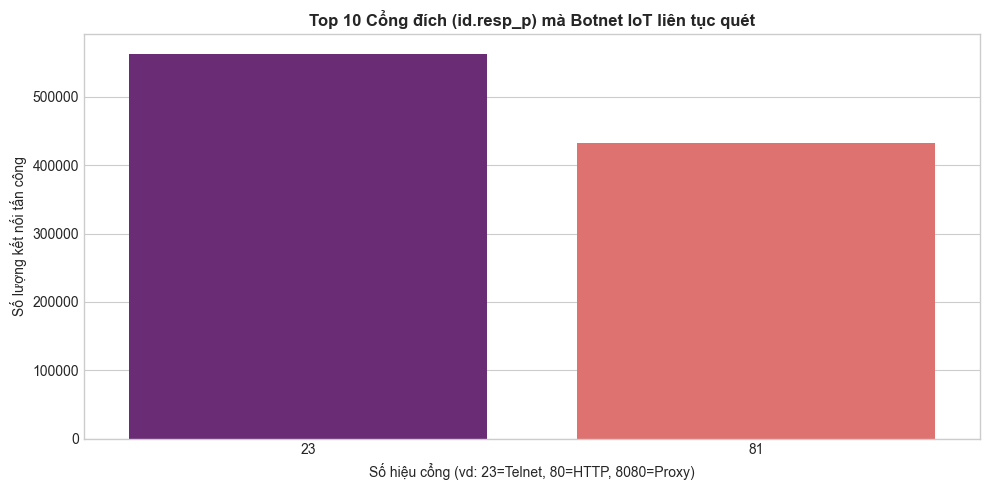

In [5]:
# 3.3 Top 10 Cổng đích (Destination Ports) bị tấn công nhiều nhất
malicious_ports = df[df["label_clean"] == "Malicious"]["id.resp_p"].value_counts().head(10)

plt.figure(figsize=(10, 5))
sns.barplot(x=malicious_ports.index.astype(str), y=malicious_ports.values, palette="magma")
plt.title("Top 10 Cổng đích (id.resp_p) mà Botnet IoT liên tục quét", fontsize=12, fontweight="bold")
plt.xlabel("Số hiệu cổng (vd: 23=Telnet, 80=HTTP, 8080=Proxy)")
plt.ylabel("Số lượng kết nối tấn công")
plt.tight_layout()
plt.show()

---
## 4. TIỀN XỬ LÝ DỮ LIỆU (Preprocessing & Feature Engineering)
Chuẩn bị 2 bộ đặc trưng:
- **Bộ 1 (Toàn bộ đặc trưng)**: Bao gồm cả `conn_state` và `history`.
- **Bộ 2 (Đối chứng - Không Leakage)**: Bỏ hẳn `conn_state` và `history` để đo sức mạnh thực sự của mô hình.

In [6]:
NUMERIC_COLS = [
    "id.orig_p", "id.resp_p", "duration", "orig_bytes", "resp_bytes",
    "missed_bytes", "orig_pkts", "orig_ip_bytes", "resp_pkts", "resp_ip_bytes"
]
CATEGORICAL_COLS = ["proto", "service", "conn_state", "history"]

df_proc = df.copy()

for col in NUMERIC_COLS:
    df_proc[col] = df_proc[col].replace("-", 0).replace("(empty)", 0)
    df_proc[col] = pd.to_numeric(df_proc[col], errors="coerce").fillna(0)

for col in CATEGORICAL_COLS:
    df_proc[col] = df_proc[col].replace("-", "UNKNOWN").replace("(empty)", "UNKNOWN")
    le = LabelEncoder()
    df_proc[col] = le.fit_transform(df_proc[col].astype(str))

y = df_proc["label_clean"].apply(lambda x: 0 if x == "Benign" else 1).values

# Bộ đầy đủ
features_full = NUMERIC_COLS + CATEGORICAL_COLS
X_full = df_proc[features_full].values

# Bộ không chứa shortcut feature
features_no_leak = [c for c in features_full if c not in ["conn_state", "history"]]
X_no_leak = df_proc[features_no_leak].values

print(f"[+] Bộ đặc trưng đầy đủ: {len(features_full)} cột")
print(f"[+] Bộ đặc trưng đối chứng: {len(features_no_leak)} cột: {features_no_leak}")

[+] Bộ đặc trưng đầy đủ: 14 cột
[+] Bộ đặc trưng đối chứng: 12 cột: ['id.orig_p', 'id.resp_p', 'duration', 'orig_bytes', 'resp_bytes', 'missed_bytes', 'orig_pkts', 'orig_ip_bytes', 'resp_pkts', 'resp_ip_bytes', 'proto', 'service']


---
## 5. HUẤN LUYỆN VÀ ĐÁNH GIÁ 5 MÔ HÌNH (Full Features)

In [ ]:
# 5. HUẤN LUYỆN TRÊN TRAIN_SET VÀ ĐÁNH GIÁ TRÊN TEST_SET ĐỘC LẬP
# Tiền xử lý trên tập Train
df_train_proc = train_df.copy()
for col in NUMERIC_COLS:
    df_train_proc[col] = pd.to_numeric(df_train_proc[col].replace("-", 0).replace("(empty)", 0), errors="coerce").fillna(0)
for col in CATEGORICAL_COLS:
    df_train_proc[col] = LabelEncoder().fit_transform(df_train_proc[col].astype(str))

X_train = df_train_proc[features_full].values
y_train = df_train_proc["label_clean"].apply(lambda x: 0 if x == "Benign" else 1).values

# Tiền xử lý trên tập Test hoàn toàn mới
df_test_proc = test_df.copy()
for col in NUMERIC_COLS:
    df_test_proc[col] = pd.to_numeric(df_test_proc[col].replace("-", 0).replace("(empty)", 0), errors="coerce").fillna(0)
for col in CATEGORICAL_COLS:
    df_test_proc[col] = LabelEncoder().fit_transform(df_test_proc[col].astype(str))

X_test = df_test_proc[features_full].values
y_test = df_test_proc["label_clean"].apply(lambda x: 0 if x == "Benign" else 1).values

print(f"[+] Dữ liệu huấn luyện: X_train {X_train.shape}, y_train {y_train.shape}")
print(f"[+] Dữ liệu kiểm thử:   X_test  {X_test.shape}, y_test  {y_test.shape}")

# Chuẩn hóa
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

models = {
    "Logistic Regression": (LogisticRegression(max_iter=500, random_state=42), True),
    "Decision Tree": (DecisionTreeClassifier(max_depth=12, random_state=42), False),
    "Random Forest": (RandomForestClassifier(n_estimators=100, max_depth=15, n_jobs=-1, random_state=42), False),
    "XGBoost": (xgb.XGBClassifier(n_estimators=100, max_depth=6, learning_rate=0.1, eval_metric="logloss", random_state=42, n_jobs=-1), False),
    "LightGBM": (lgb.LGBMClassifier(n_estimators=100, max_depth=6, learning_rate=0.1, random_state=42, n_jobs=-1, verbose=-1), False)
}

results = []
cms = {}

for name, (clf, use_scaled) in models.items():
    X_tr = X_train_scaled if use_scaled else X_train
    X_te = X_test_scaled if use_scaled else X_test
    
    t0 = time.time()
    clf.fit(X_tr, y_train)
    t_train = time.time() - t0
    
    y_pred = clf.predict(X_te)
    
    results.append({
        "Mô Hình": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall (Detection Rate)": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0),
        "Thời gian Train (s)": t_train
    })
    cms[name] = confusion_matrix(y_test, y_pred)

benchmark_df = pd.DataFrame(results)
benchmark_df

NameError: name 'train_df' is not defined

: 

---
## 6. MA TRẬN NHẦM LẪN (Confusion Matrix)

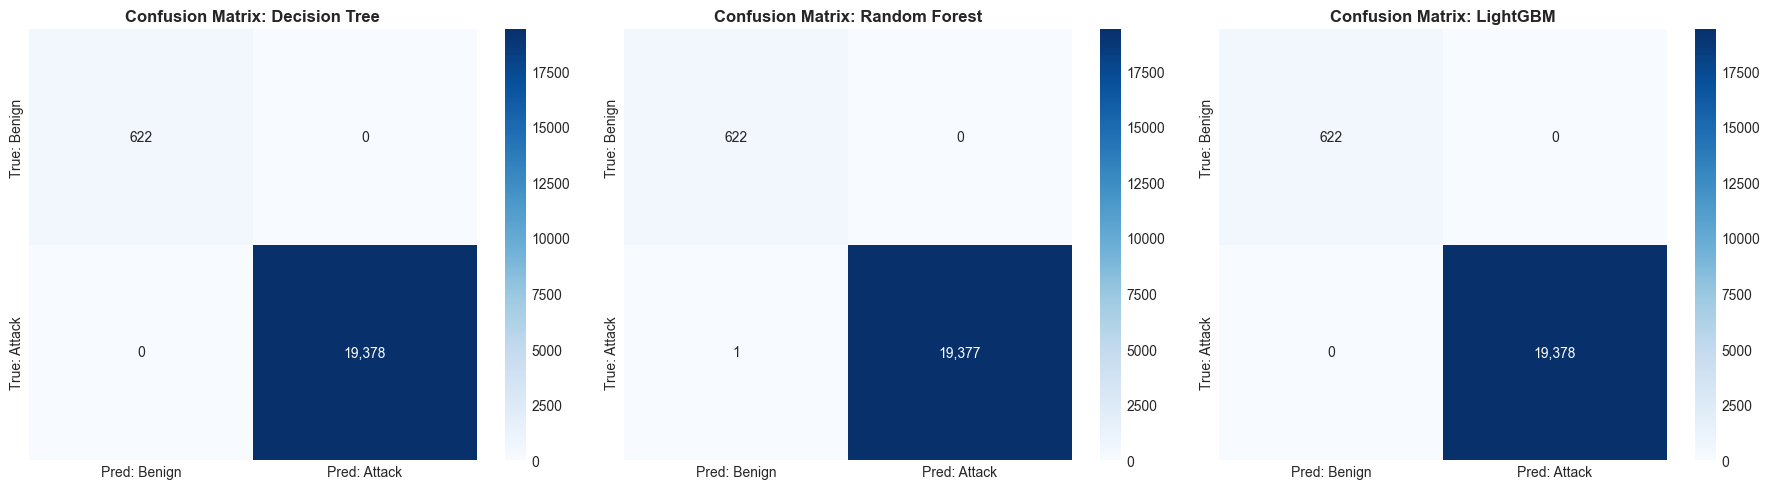

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
display_models = ["Decision Tree", "Random Forest", "LightGBM"]

for idx, m_name in enumerate(display_models):
    sns.heatmap(cms[m_name], annot=True, fmt=",d", cmap="Blues",
                xticklabels=["Pred: Benign", "Pred: Attack"],
                yticklabels=["True: Benign", "True: Attack"], ax=axes[idx])
    axes[idx].set_title(f"Confusion Matrix: {m_name}", fontsize=12, fontweight="bold")

plt.tight_layout()
plt.show()

---
## 7. THÍ NGHIỆM ĐỐI CHỨNG: KHI LOẠI BỎ ĐẶC TRƯNG SHORTCUT
Đánh giá lại Random Forest và LightGBM trên bộ dữ liệu không chứa `conn_state` và `history`.

c:\Users\ADMIN\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_12108\4221744886.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=imp.values, y=imp.index, palette="viridis")


=== BÁO CÁO PHÂN LOẠI KHI KHÔNG DÙNG SHORTCUT FEATURES ===
              precision    recall  f1-score   support

      Benign       1.00      0.98      0.99       622
   Malicious       1.00      1.00      1.00     19378

    accuracy                           1.00     20000
   macro avg       1.00      0.99      0.99     20000
weighted avg       1.00      1.00      1.00     20000



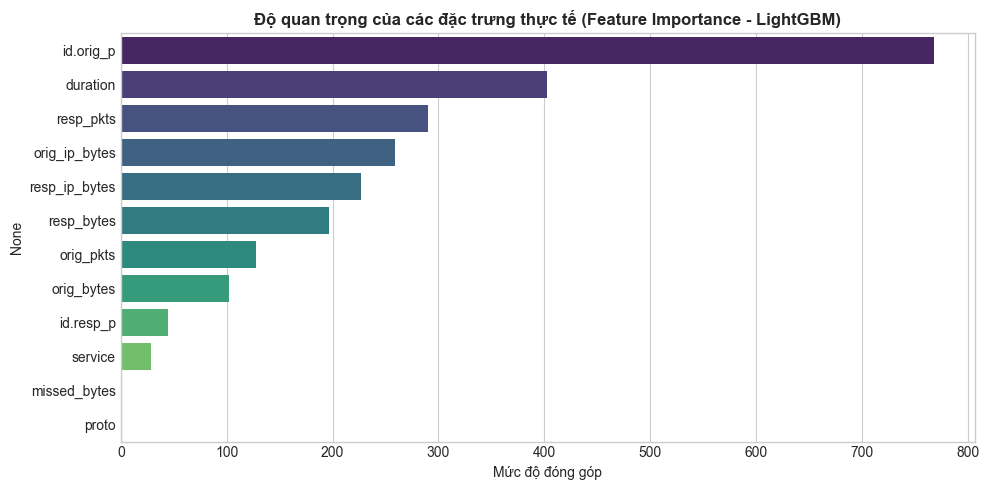

In [ ]:
X_tr_nl, X_te_nl, y_tr_nl, y_te_nl = train_test_split(
    X_no_leak, y, test_size=0.2, random_state=42, stratify=y
)

lgb_nl = lgb.LGBMClassifier(n_estimators=100, max_depth=6, learning_rate=0.1, random_state=42, n_jobs=-1, verbose=-1)
lgb_nl.fit(X_tr_nl, y_tr_nl)
y_pred_nl = lgb_nl.predict(X_te_nl)

print("=== BÁO CÁO PHÂN LOẠI KHI KHÔNG DÙNG SHORTCUT FEATURES ===")
print(classification_report(y_te_nl, y_pred_nl, target_names=["Benign", "Malicious"]))

# Độ quan trọng của các đặc trưng thực tế
imp = pd.Series(lgb_nl.feature_importances_, index=features_no_leak).sort_values(ascending=False)
plt.figure(figsize=(10, 5))
sns.barplot(x=imp.values, y=imp.index, palette="viridis")
plt.title("Độ quan trọng của các đặc trưng thực tế (Feature Importance - LightGBM)", fontsize=12, fontweight="bold")
plt.xlabel("Mức độ đóng góp")
plt.tight_layout()
plt.show()

---
## 8. MINH HỌA SUY LUẬN THỰC TẾ (INFERENCE TEST 10 DÒNG)
Trích xuất 10 dòng ngẫu nhiên từ tập Test (bao gồm cả luồng sạch Benign và luồng tấn công Malicious) để quan sát mô hình LightGBM phân biệt và chấm điểm độ tin cậy (Confidence Probability).

In [ ]:
# Chon 10 dong gom ca Benign va Malicious
y_proba = clf.predict_proba(X_test)
test_results_df = pd.DataFrame(X_test, columns=features_full)
test_results_df["NHAN_THUC_TE"] = np.where(y_test == 0, "Benign (Sach)", "Malicious (Doc)")
test_results_df["MODEL_DU_DOAN"] = np.where(y_pred == 0, "Benign (Sach)", "Malicious (Doc)")
test_results_df["DO_TIN_CAY"] = [f"{np.max(p)*100:.1f}%" for p in y_proba]
test_results_df["KET_QUA"] = np.where(test_results_df["NHAN_THUC_TE"] == test_results_df["MODEL_DU_DOAN"], "DUNG [OK]", "SAI [FAIL]")

s_benign = test_results_df[test_results_df["NHAN_THUC_TE"] == "Benign (Sach)"].head(5)
s_mal = test_results_df[test_results_df["NHAN_THUC_TE"] == "Malicious (Doc)"].head(5)
sample_10 = pd.concat([s_benign, s_mal]).sample(frac=1, random_state=42)

cols_display = ["proto", "id.resp_p", "duration", "orig_bytes", "resp_bytes", "conn_state", "NHAN_THUC_TE", "MODEL_DU_DOAN", "DO_TIN_CAY", "KET_QUA"]
print("=== 10 DONG MINH HOA MODEL CHAY THUC TE TREN TAP TEST ===\n")
sample_10[cols_display]